# 10. Modelo original (CS-FOF) y métodos recientes

Las 112 combinaciones de los notebooks 04 a 09 son los modelos tradicionales y fijan el punto de comparación: su mejor F1 medio (validación anidada 5 x 5) es el de **XGBoost con `class_weight` y optimización bayesiana, 0.5466**. Este notebook responde una sola pregunta: **¿existe un modelo que supere ese F1?**

Para responderla se agregan tres modelos con el mismo protocolo (mismos 5 folds externos y 5 internos, semilla 42, F1 de la clase *default* como métrica):

- **CS-FOF** (*Cost-Sensitive Fisher Oblique Forest*), el modelo original del proyecto, programado desde cero con `numpy` en `src/original_model.py`.
- **LightGBM** y **CatBoost**, dos métodos recientes de boosting, como referencia del estado del arte.

Los resultados son parciales, porque las corridas de los modelos nuevos todavía no terminan. Provienen de `results/experiments_5x5__cs_fof.csv` (4 combinaciones) y `results/experiments_5x5__boosting_recientes.csv` (25 combinaciones: 16 de LightGBM y 9 de CatBoost, sin ADASYN), unidos a las 112 en `results/master_table_e3.csv` (141 filas).

## 1. La idea de CS-FOF

Un árbol clásico corta sobre una sola variable a la vez. Pero el riesgo de *default* depende de combinaciones (por ejemplo, del límite de crédito junto con lo pagado el mes anterior), de modo que la frontera es oblicua. En cada nodo, CS-FOF compara dos tipos de corte y se queda con el mejor:

1. **Cortes rectos**, como en Random Forest: umbrales sobre $\sqrt{p}$ variables sorteadas.
2. **Un corte oblicuo** en la dirección discriminante de Fisher, calculada solo con los clientes del nodo y ponderando más a los que incumplen (para penalizar más el falso negativo). Con $\mu_0$ y $\mu_1$ las medias de cada clase y $S_w$ la matriz de dispersión intraclase ponderada,

$$
v = S_w^{-1}\left(\mu_1 - \mu_0\right), \qquad z = v^\top x .
$$

El nodo elige el corte de mayor reducción de impureza de Gini ponderada $\Delta G$:

$$
G = 1 - p_0^2 - p_1^2, \qquad
\Delta G = G_{\text{padre}} - \frac{W_L}{W}\,G_L - \frac{W_R}{W}\,G_R .
$$

Como el corte oblicuo compite con todos los rectos, el corte elegido nunca es peor que el mejor recto **en los datos de entrenamiento**:

$$
\Delta G(\text{elegido}) \;\ge\; \max_j \Delta G(\text{recto}_j).
$$

Esto no garantiza que el bosque completo prediga mejor en clientes nuevos; eso solo lo pueden decir las pruebas de las secciones 3 y 4.

In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

pd.options.display.float_format = "{:,.4f}".format
RES = config.RESULTS_DIR
COMP = config.PROJECT_ROOT / "experiments" / "comparacion_final"

NUEVOS = ["cs_fof", "lightgbm", "catboost"]
tabla = pd.read_csv(RES / "master_table_e3.csv")
tabla["grupo"] = np.where(tabla["model"].isin(NUEVOS), "nuevo", "tradicional")
print("Filas:", len(tabla), "|", tabla["grupo"].value_counts().to_dict())
print(tabla.groupby("model").size().sort_values(ascending=False).to_string())

Filas: 141 | {'tradicional': 112, 'nuevo': 29}
model
knn                    16
decision_tree          16
naive_bayes            16
random_forest          16
lightgbm               16
logistic_regression    16
svm                    16
xgboost                16
catboost                9
cs_fof                  4


## 2. Mejor combinación de cada modelo

Para cada modelo se toma la combinación (técnica de balanceo y método de optimización) con mayor F1 medio en los 5 folds externos. La desviación estándar usa `ddof=1`.

In [2]:
mejores = (tabla.loc[tabla.groupby("model")["f1_mean"].idxmax()]
           .sort_values("f1_mean", ascending=False)
           .reset_index(drop=True))
mejores.insert(0, "puesto", mejores.index + 1)
vista = mejores[["puesto", "model", "grupo", "technique", "method",
                 "f1_mean", "f1_std", "precision_mean", "recall_mean", "roc_auc_mean"]]
vista

,puesto,model,grupo,technique,method,f1_mean,f1_std,precision_mean,recall_mean,roc_auc_mean
0,1,catboost,nuevo,class_weight,random_search,0.5480,0.0088,0.4840,0.6317,0.7838
1,2,cs_fof,nuevo,class_weight,random_search,0.5479,0.0054,0.5148,0.5864,0.7847
2,3,xgboost,tradicional,class_weight,bayesian_optuna,0.5466,0.0091,0.4927,0.6149,0.7828
3,4,lightgbm,nuevo,class_weight,bayesian_optuna,0.5462,0.0086,0.4878,0.6207,0.7843
4,5,random_forest,tradicional,class_weight,random_search,0.5452,0.0077,0.4974,0.6041,0.7831
5,6,svm,tradicional,smote,random_search,0.5387,0.0048,0.4795,0.6148,0.7638
6,7,knn,tradicional,class_weight,random_search,0.5264,0.0122,0.4569,0.6208,0.7629
7,8,decision_tree,tradicional,class_weight,bayesian_optuna,0.5254,0.0043,0.4788,0.5854,0.7569
8,9,logistic_regression,tradicional,class_weight,genetic_deap,0.5182,0.0104,0.4484,0.6139,0.7449
9,10,naive_bayes,tradicional,smote,grid_search,0.4987,0.0078,0.4136,0.6279,0.7454


In [3]:
trad = tabla[tabla["grupo"] == "tradicional"]
ref = trad.loc[trad["f1_mean"].idxmax()]
print(f"Mejor de las 112 combinaciones: {ref['model']} / {ref['technique']} / {ref['method']}")
print(f"F1 medio = {ref['f1_mean']:.4f} (desv. {ref['f1_std']:.4f})\n")

nuevos = mejores[mejores["grupo"] == "nuevo"][["model", "f1_mean", "f1_std"]].copy()
nuevos["dif. frente a las 112"] = nuevos["f1_mean"] - ref["f1_mean"]
nuevos

Mejor de las 112 combinaciones: xgboost / class_weight / bayesian_optuna
F1 medio = 0.5466 (desv. 0.0091)



,model,f1_mean,f1_std,dif. frente a las 112
0,catboost,0.5480,0.0088,0.0015
1,cs_fof,0.5479,0.0054,0.0014
3,lightgbm,0.5462,0.0086,-0.0004


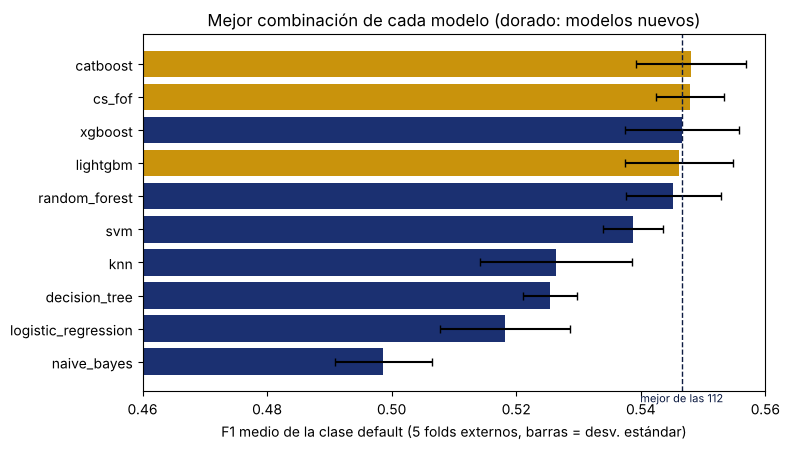

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colores = ["#C9930C" if g == "nuevo" else "#1B3071" for g in mejores["grupo"]]
ax.barh(mejores["model"][::-1], mejores["f1_mean"][::-1], xerr=mejores["f1_std"][::-1],
        color=colores[::-1], capsize=3)
ax.axvline(ref["f1_mean"], color="#0C1A41", ls="--", lw=1)
ax.text(ref["f1_mean"], -0.9, "mejor de las 112", ha="center", va="top", fontsize=8, color="#0C1A41")
ax.set_xlim(0.46, 0.56)
ax.set_xlabel("F1 medio de la clase default (5 folds externos, barras = desv. estándar)")
ax.set_title("Mejor combinación de cada modelo (dorado: modelos nuevos)")
plt.tight_layout(); plt.show()

**Lectura.** CatBoost (0.5480) y CS-FOF (0.5479) superan al mejor de las 112 por 0.0015 y 0.0014 de F1, y LightGBM (0.5462) queda 0.0004 por debajo. Las tres diferencias son de milésimas, mucho menores que la desviación entre folds (cerca de 0.009).

## 3. ¿La diferencia de CS-FOF es significativa?

Se compara CS-FOF con la mejor combinación de cada rival, fold a fold. Como los 5 folds comparten datos de entrenamiento, el $t$ de Nadeau y Bengio corrige la varianza de la diferencia entre folds. Con $d_i$ la diferencia de F1 en el fold $i$, $k=5$ folds, $n_1$ y $n_2$ los tamaños de entrenamiento y prueba:

$$
t = \frac{\bar d}{\sqrt{\left(\dfrac{1}{k} + \dfrac{n_2}{n_1}\right) s_d^2}} .
$$

También se reporta el Wilcoxon por pares (con 5 folds su valor mínimo posible es 0.0625) y el delta de Cliff como tamaño de efecto. Ambos $p$-valores se corrigen con Holm.

In [5]:
cmp_ = pd.read_csv(COMP / "cs_fof_vs_modelos.csv")
cmp_ = cmp_.rename(columns={"modelo": "rival", "dif_f1": "F1 CS-FOF menos rival", "gana": "folds que gana CS-FOF (de 5)",
                            "p_nadeau_bengio_holm": "p Nadeau-Bengio (Holm)", "p_wilcoxon_holm": "p Wilcoxon (Holm)"})
cmp_[["rival", "F1 CS-FOF menos rival", "folds que gana CS-FOF (de 5)", "cliff",
      "p_nadeau_bengio", "p Nadeau-Bengio (Holm)", "p Wilcoxon (Holm)"]]

,rival,F1 CS-FOF menos rival,folds que gana CS-FOF (de 5),cliff,p_nadeau_bengio,p Nadeau-Bengio (Holm),p Wilcoxon (Holm)
0,catboost,-0.0001,2,-0.0400,0.9743,1.0000,1.0000
1,xgboost,0.0014,4,0.3600,0.6266,1.0000,1.0000
2,lightgbm,0.0018,3,0.1200,0.5673,1.0000,1.0000
3,random_forest,0.0027,4,0.3600,0.3093,1.0000,0.7500
4,svm,0.0092,5,0.7600,0.0023,0.0141,0.5625
5,knn,0.0216,5,0.9200,0.0113,0.0563,0.5625
6,decision_tree,0.0225,5,1.0000,0.0004,0.0033,0.5625
7,logistic_regression,0.0297,5,1.0000,0.0020,0.0141,0.5625
8,naive_bayes,0.0493,5,1.0000,0.0000,0.0003,0.5625


**Lectura.** Frente a CatBoost, XGBoost, LightGBM y Random Forest las diferencias son menores a 0.003 de F1 y ningún $p$-valor corregido es significativo: no hay evidencia de que CS-FOF sea mejor, ni peor, que ellos. En cambio, supera a SVM, KNN, árbol de decisión, regresión logística y Naive Bayes (diferencias de 0.009 a 0.049 de F1 y $p$ de Nadeau-Bengio con Holm menor a 0.06 en los cinco, y delta de Cliff de 0.76 a 1). El Wilcoxon con 5 folds no alcanza a ser significativo en ningún caso.

## 4. Ranking global: Friedman y Nemenyi

Se ordenan los 10 modelos (la mejor combinación de cada uno) por rango medio de F1 en los 5 folds. La prueba de Friedman contrasta si todos son equivalentes; si no, la diferencia crítica de Nemenyi indica cuándo dos rangos medios se separan:

$$
\mathrm{CD} = q_\alpha \sqrt{\frac{k(k+1)}{6N}}, \qquad k = 10 \text{ modelos},\; N = 5 \text{ folds}.
$$

Friedman: chi2 = 40.29, p = 6.74e-06
Diferencia crítica de Nemenyi (CD) = 6.06



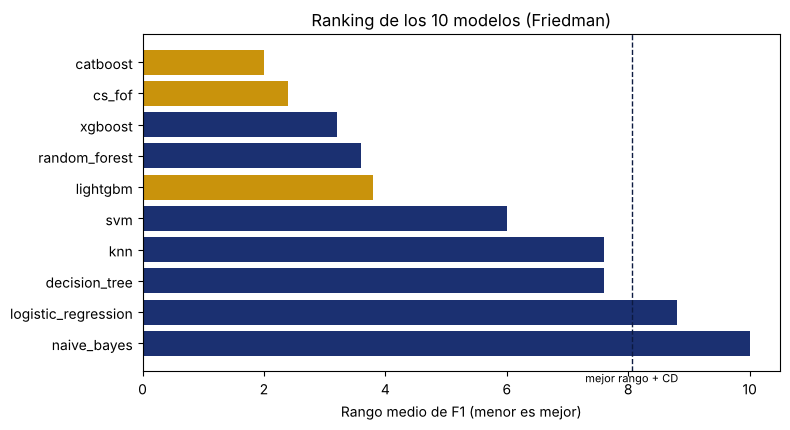

Modelos que Nemenyi no separa del mejor: catboost, cs_fof, xgboost, random_forest, lightgbm, svm, knn, decision_tree


In [6]:
fr = json.load(open(COMP / "friedman.json"))
print(f"Friedman: chi2 = {fr['friedman_chi2']:.2f}, p = {fr['friedman_p']:.2e}")
print(f"Diferencia crítica de Nemenyi (CD) = {fr['nemenyi_cd']:.2f}\n")

rangos = pd.Series(fr["rangos"]).sort_values()
mejor_rango = rangos.iloc[0]
fig, ax = plt.subplots(figsize=(8, 4.4))
cols = ["#C9930C" if m in NUEVOS else "#1B3071" for m in rangos.index]
ax.barh(rangos.index[::-1], rangos.values[::-1], color=cols[::-1])
ax.axvline(mejor_rango + fr["nemenyi_cd"], color="#0C1A41", ls="--", lw=1)
ax.text(mejor_rango + fr["nemenyi_cd"], -0.9, "mejor rango + CD", ha="center", va="top", fontsize=8)
ax.set_xlabel("Rango medio de F1 (menor es mejor)")
ax.set_title("Ranking de los 10 modelos (Friedman)")
plt.tight_layout(); plt.show()

dentro = rangos[rangos <= mejor_rango + fr["nemenyi_cd"]]
print("Modelos que Nemenyi no separa del mejor:", ", ".join(dentro.index))

**Lectura.** Friedman es significativo, pero Nemenyi con solo 5 folds es poco potente: solo separa de la cabeza a regresión logística y Naive Bayes. CatBoost, CS-FOF, XGBoost, Random Forest y LightGBM ocupan los cinco primeros rangos, pero entre ellos (y aun frente a SVM, KNN y el árbol de decisión) el orden no es estadísticamente interpretable. Se lee como una comparación descriptiva.

## 5. Comparación sobre las mismas predicciones: DeLong y McNemar

Con las probabilidades fuera de muestra (*out-of-fold*) de cada modelo se comparan sus AUC con la prueba de DeLong y sus aciertos con McNemar (sobre los clientes en que solo uno de los dos falla). Con unos 30,000 clientes, McNemar detecta diferencias minúsculas en los aciertos, por lo que se interpreta junto con el tamaño de la diferencia de F1 de la sección anterior.

In [7]:
dm = pd.read_csv(COMP / "delong_mcnemar.csv")
dm[["rival", "auc_cs_fof", "auc_rival", "delong_p", "mcnemar_solo_cs_fof_falla",
    "mcnemar_solo_rival_falla", "f1_oof_cs_fof", "f1_oof_rival"]]

,rival,auc_cs_fof,auc_rival,delong_p,mcnemar_solo_cs_fof_falla,mcnemar_solo_rival_falla,f1_oof_cs_fof,f1_oof_rival
0,catboost,0.7833,0.7843,0.2727,429,936,0.5484,0.5470
1,xgboost,0.7833,0.7827,0.5606,434,827,0.5484,0.5448
2,lightgbm,0.7833,0.7725,0.0000,345,782,0.5484,0.5459
3,random_forest,0.7833,0.7822,0.1714,313,615,0.5484,0.5434


**Lectura.** El AUC de CS-FOF es indistinguible del de CatBoost, XGBoost y Random Forest (DeLong con $p > 0.1$) y mayor que el de LightGBM (DeLong con $p < 0.001$). McNemar sí marca diferencias en los aciertos individuales, pero esas diferencias se compensan: el F1 fuera de muestra de CS-FOF y de cada rival difiere en menos de 0.003.

## 6. Conclusión (parcial)

- **Respuesta a la pregunta con los resultados disponibles.** Ningún modelo nuevo supera de forma significativa al mejor de las 112 combinaciones. El mayor F1 medio es de CatBoost (0.5480), seguido de CS-FOF (0.5479); frente al mejor tradicional (XGBoost, 0.5466) la ventaja es de 0.001 a 0.002, menor que la desviación entre folds.
- **CS-FOF** es competitivo, con el mayor ROC-AUC medio y la menor variación entre folds entre los cinco primeros, pero empata estadísticamente con CatBoost, XGBoost, LightGBM y Random Forest.
- **Estado de las corridas.** Los resultados son parciales: las corridas de los modelos nuevos todavía no terminan (hasta ahora CS-FOF con 4 combinaciones, LightGBM con 16 y CatBoost con 9 de 16). Esta sección y las tablas se actualizan cuando se completen.
- **Limitación metodológica.** Con 5 folds las pruebas tienen poca potencia, así que la comparación entre los modelos de cabeza es descriptiva.